# 03. 得点をそろえたうえでの群のずれ（較正の O/E）

02 では、群を「しきい値 0.5 の見落とし（FPR）」で探した。画像を見る空間（モデル自身の特徴・RAD-DINO）では、
これは決定境界の「所見なし」側の画像（難しい陰性）を切り出すだけになり、FPR が 0.8〜1.0 の群が自明に見つかる。
FPR は得点の関数なので、得点を予測できる空間なら群の FPR はいくらでも悪くできる。

群に特有のずれは、得点をそろえたうえで残る分として測る。val 全体で logit 差を再較正した確率 p（3 次スプラインのロジスティック回帰）に対し、
群の陽性数（No Finding）の O/E を見る（calibration-in-the-small）。multiaccuracy（Kim et al.）が抑える量そのものは
平均残差 (O − E)/n（差）で、log O/E（比）はここで選んだ要約。両方で群を選び、選ばれる群が変わるかを 5 節で見る。

- log O/E < 0：その群では、モデルが No Finding の確率を実際より高く出している。これは確率の上のずれで、
  しきい値 0.5 の見落とし（FPR）が多いことを意味しない。得点の低い群なら、確率が高めでも 0.5 を超えない
- 較正のずれは性能の gap ではない。見つけた群の FPR・TPR・AUROC と補集合との差は 5 節で別に測る
- 群ごとの切片の補正（属性・潜在の条件付け）で直せるのは、この種類のずれ。難しい画像（較正は合っていて得点が
  あいまい）は、群の条件付けでは直らない

群の作り方は 02 と同じクラスタリング（GEORGE は真のクラスで群を分けるので O/E が自明に極端になり、外す）に、Kim et al. の形の監査器（再較正した残差 y − p を入力から予測）を足す。
基準として、得点そのものの十分位（較正が合っていれば O/E のばらつきは帰無分布と同じになるはず）も並べる。

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import rootutils
from IPython.display import display

ROOT = rootutils.setup_root(Path.cwd(), indicator=".project-root", pythonpath=True)
from analysis.common.paths import STYLE_SHEET, study_dir  # noqa: E402
from analysis.latent_subgroup_spaces import subgroups as sg  # noqa: E402

plt.style.use(STYLE_SHEET)
PACKAGE = study_dir("latent_subgroup_spaces")
TOPIC = "03_calibration_bias"
RESULTS = PACKAGE / "results" / TOPIC
FIGURES = PACKAGE / "figures" / TOPIC
RESULTS.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)

RUNS = {
    42: "20261002T125005Z-spatial-lora-chexpert-race-known-s42-a21c",
    43: "20261002T145233Z-spatial-lora-chexpert-race-known-s43-424e",
    44: "20261002T165551Z-spatial-lora-chexpert-race-known-s44-eb13",
}
K_CLUSTER = 8
RIDGE_BINS = 8
TREE_MIN_LEAF = 500
# LHCF の K は 02 の BIC で選んだ値（3 seed とも特徴 12、RAD-DINO 11）。
LHCF_K = {"feat32": 12, "rad32": 11}

## 読み込みと再較正

再較正は val 全体の、logit 差の 3 次スプラインのロジスティック回帰（群を見ない変換）。Platt（1 次）では得点の十分位で O/E のずれが残った。test の全体 O/E が 1 に近いことを確かめる。

In [2]:
DATA, SPACES, PROB = {}, {}, {}
calibration_rows = []
for seed, run_id in RUNS.items():
    DATA[seed], SPACES[seed] = sg.build_spaces(run_id)
    val, test = DATA[seed]["val"].frame, DATA[seed]["test"].frame
    PROB[seed] = sg.recalibrate(val, test)
    for split, frame, p in (("val", val, PROB[seed][0]), ("test", test, PROB[seed][1])):
        calibration_rows.append({"seed": seed, "split": split, "observed": frame.target.sum(), "expected": p.sum(), "raw_expected": frame.p.sum()})
display(pd.DataFrame(calibration_rows).assign(oe=lambda d: d.observed / d.expected, raw_oe=lambda d: d.observed / d.raw_expected).round(3))

,seed,split,observed,expected,raw_expected,oe,raw_oe
0,42,val,1980,1980.919,7746.762207,1.000,0.256
1,42,test,2044,2002.445,7736.231934,1.021,0.264
2,43,val,1980,1978.003,5931.920898,1.001,0.334
3,43,test,2044,1988.946,5945.129883,1.028,0.344
4,44,val,1980,1978.276,6372.461914,1.001,0.311
5,44,test,2044,1996.642,6394.824219,1.024,0.320


## 群を作る

`score deciles` は得点の十分位（較正の基準）。監査器は再較正した残差を当てる。

In [3]:
def build_partitions(seed):
    space = SPACES[seed]
    val, test = DATA[seed]["val"].frame, DATA[seed]["test"].frame
    p_val, p_test = PROB[seed]
    y_val = val.target.to_numpy()
    edges = np.quantile(p_val, np.linspace(0, 1, 11)[1:-1])
    out = {
        "score deciles": (np.digitize(p_val, edges), np.digitize(p_test, edges)),
        "attributes / 8 groups": (val.attr8.to_numpy(), test.attr8.to_numpy()),
        "attributes / 48 fine cells": (val.fine48.to_numpy(), test.fine48.to_numpy()),
        "c / k-means": sg.kmeans_groups(*space["c"], K_CLUSTER),
        "dW / k-means": sg.kmeans_groups(*space["dW"], K_CLUSTER),
        "feat / LHCF": sg.gmm_groups(*space["feat32"], LHCF_K["feat32"]),
        "RAD-DINO / LHCF": sg.gmm_groups(*space["rad32"], LHCF_K["rad32"]),
    }
    audit_inputs = {"attributes": space["attributes"], "c": space["c"], "feat": space["feat64"], "RAD-DINO": space["rad64"]}
    for name, (val_x, test_x) in audit_inputs.items():
        out[f"{name} / audit ridge"] = sg.residual_auditor(val_x, test_x, y_val, p_val, "ridge", RIDGE_BINS)
        out[f"{name} / audit tree"] = sg.residual_auditor(val_x, test_x, y_val, p_val, "tree", TREE_MIN_LEAF)
    return out


PARTITIONS = {(seed, name): groups for seed in RUNS for name, groups in build_partitions(seed).items()}
METHODS = list(dict.fromkeys(name for _, name in PARTITIONS))

## 1. 横並び：較正のずれ

- `oe_sd`：test の log O/E の SD（期待陽性数で重み付け）。`oe_sd_null` は y を Bernoulli(p) で引き直したときの平均で、
  較正が完全でも群の小ささで出る分。`oe_sd` がこれを超えた分が、群が捉えた較正のずれ
- `val_chosen_test_log_oe`：val で O/E が最小（No Finding を最も出しすぎ）の群の、test の log O/E
- `nmi_inputs`：群がモデル入力の属性（年齢 65 歳・性別・race・撮影の向き）でどれだけ決まるか

In [4]:
rows = []
for (seed, name), (val_groups, test_groups) in PARTITIONS.items():
    val, test = DATA[seed]["val"].frame, DATA[seed]["test"].frame
    p_val, p_test = PROB[seed]
    row = sg.summarize_calibration(name, val_groups, test_groups, val.target.to_numpy(), p_val, test.target.to_numpy(), p_test)
    row.update(
        seed=seed,
        nmi_attr8=sg.explained_by(test_groups, test, ["age65", "race_group"]),
        nmi_inputs=sg.explained_by(test_groups, test, ["age65", "sex", "race_group", "view"]),
    )
    rows.append(row)
comparison = pd.DataFrame(rows)
comparison.to_csv(RESULTS / "calibration_by_seed.csv", index=False)
columns = ["groups_valid", "oe_sd", "oe_sd_null", "oe_sd_p", "val_chosen_val_log_oe", "val_chosen_test_log_oe", "val_chosen_test_n", "val_chosen_test_expected", "nmi_attr8", "nmi_inputs"]
comparison_mean = comparison.groupby("partition", sort=False)[columns].mean().loc[METHODS]
comparison_mean.to_csv(RESULTS / "calibration_mean.csv")
display(comparison_mean.round(3))

,groups_valid,oe_sd,oe_sd_null,oe_sd_p,val_chosen_val_log_oe,val_chosen_test_log_oe,val_chosen_test_n,val_chosen_test_expected,nmi_attr8,nmi_inputs
partition,,,,,,,,,,
score deciles,10.000,0.093,0.066,0.055,-0.252,0.099,1955.333,36.067,0.026,0.039
attributes / 8 groups,8.000,0.074,0.051,0.098,-0.073,-0.075,948.333,106.309,1.000,0.699
attributes / 48 fine cells,34.000,0.117,0.109,0.365,-0.428,-0.074,334.000,28.037,0.699,1.000
c / k-means,8.000,0.096,0.052,0.048,-0.135,-0.126,2867.000,271.903,0.308,0.500
dW / k-means,8.000,0.071,0.052,0.161,-0.135,-0.064,3174.333,352.958,0.259,0.422
feat / LHCF,12.000,0.103,0.071,0.164,-0.410,-0.164,1947.000,33.309,0.020,0.202
RAD-DINO / LHCF,10.000,0.118,0.059,0.005,-0.262,-0.024,2393.000,92.347,0.010,0.330
attributes / audit ridge,8.000,0.100,0.051,0.007,-0.172,-0.060,2167.333,189.982,0.225,0.508
attributes / audit tree,28.333,0.138,0.101,0.085,-0.474,-0.082,644.000,47.372,0.390,0.515


### seed をまたいだ一致（test の ARI）

In [5]:
ari = pd.Series({name: sg.seed_agreement({seed: PARTITIONS[(seed, name)][1] for seed in RUNS}) for name in METHODS}, name="seed_ari")
ari.to_csv(RESULTS / "seed_ari.csv")
display(ari.round(2))

score deciles                 0.19
attributes / 8 groups         1.00
attributes / 48 fine cells    1.00
c / k-means                   0.45
dW / k-means                  0.47
feat / LHCF                   0.25
RAD-DINO / LHCF               1.00
attributes / audit ridge      0.23
attributes / audit tree       0.50
c / audit ridge               0.18
c / audit tree                0.33
feat / audit ridge            0.01
feat / audit tree             0.03
RAD-DINO / audit ridge        0.12
RAD-DINO / audit tree         0.04
Name: seed_ari, dtype: float64

## 2. 最も No Finding を出しすぎている群の中身

val で O/E が最小の群を選び、test の全行での要因の割合を全体と比べる（3 seed の比の平均）。
病種は CheXbert（impression）で陽性のもの。陽性（No Finding）の行は病種を持たないので、病種の比は陰性の構成も含めて読む。

In [6]:
FACTORS = [
    "young", "female", "black", "asian", "pa", "lateral", "affirmed_normal",
    *sg.CONTEXT_FLAGS, *[f"dz_{name}" for name in sg.DISEASES],
]


def with_factor_columns(frame):
    return frame.assign(
        young=frame.age65 == 0,
        female=frame.sex == 1,
        black=frame.race_group == 3,
        asian=frame.race_group == 2,
        pa=frame.view == 1,
        lateral=frame.view == 2,
        affirmed_normal=frame.report_type == "affirmed_normal",
    )


def share_ratio(mask, frame):
    inside, everyone = frame[mask], frame
    return pd.DataFrame(
        {"factor": FACTORS, "share_in_group": [inside[f].mean() for f in FACTORS], "share_overall": [everyone[f].mean() for f in FACTORS]}
    ).assign(ratio=lambda d: d.share_in_group / d.share_overall)


enrich_rows, chosen_rows = [], []
for (seed, name), (val_groups, test_groups) in PARTITIONS.items():
    val, test = DATA[seed]["val"].frame, DATA[seed]["test"].frame
    p_val, p_test = PROB[seed]
    chosen = sg.calibration_table(val_groups, val.target.to_numpy(), p_val).log_oe.idxmin()
    mask = test_groups == chosen
    frame = with_factor_columns(test)
    enrich_rows.append(share_ratio(mask, frame).assign(seed=seed, partition=name))
    chosen_rows.append(
        {
            "seed": seed,
            "partition": name,
            "n": int(mask.sum()),
            "prevalence": test.target[mask].mean(),
            "mean_p": p_test[mask].mean(),
            "fpr": test.pred[mask & (test.target == 0)].mean(),
            "overall_fpr": test.pred[test.target == 0].mean(),
        }
    )
enrich = pd.concat(enrich_rows, ignore_index=True)
enrich.to_csv(RESULTS / "worst_group_enrichment.csv", index=False)
chosen_table = pd.DataFrame(chosen_rows)
chosen_table.to_csv(RESULTS / "worst_group_rates.csv", index=False)
display(chosen_table.groupby("partition", sort=False).mean(numeric_only=True).drop(columns="seed").loc[METHODS].round(3))
display(enrich.pivot_table(index="factor", columns="partition", values="ratio", aggfunc="mean")[METHODS].loc[FACTORS].round(2))

,n,prevalence,mean_p,fpr,overall_fpr
partition,,,,,
score deciles,1955.333,0.020,0.018,0.000,0.246
attributes / 8 groups,948.333,0.111,0.115,0.283,0.246
attributes / 48 fine cells,334.000,0.078,0.084,0.213,0.246
c / k-means,2867.000,0.086,0.097,0.243,0.246
dW / k-means,3174.333,0.111,0.118,0.275,0.246
feat / LHCF,1947.000,0.015,0.018,0.005,0.246
RAD-DINO / LHCF,2393.000,0.038,0.039,0.095,0.246
attributes / audit ridge,2167.333,0.083,0.088,0.216,0.246
attributes / audit tree,644.000,0.074,0.079,0.208,0.246


partition,score deciles,attributes / 8 groups,attributes / 48 fine cells,c / k-means,dW / k-means,feat / LHCF,RAD-DINO / LHCF,attributes / audit ridge,attributes / audit tree,c / audit ridge,c / audit tree,feat / audit ridge,feat / audit tree,RAD-DINO / audit ridge,RAD-DINO / audit tree
factor,,,,,,,,,,,,,,,
young,0.89,1.22,1.84,1.42,1.63,1.04,0.91,1.16,0.61,1.72,0.09,1.15,0.84,1.06,0.85
female,0.95,1.10,0.00,0.97,0.53,0.88,0.77,0.77,1.15,0.53,0.78,0.78,0.80,0.90,0.63
black,0.93,0.00,0.00,0.47,0.89,0.85,0.99,0.50,0.35,0.46,0.66,0.97,0.94,0.95,0.84
asian,0.89,10.75,16.12,0.63,0.72,0.96,0.96,0.52,0.99,0.89,0.00,1.10,0.91,1.09,0.98
pa,0.64,1.10,0.00,0.00,0.07,0.11,0.02,0.12,0.21,0.23,0.10,1.01,0.87,0.86,0.25
lateral,0.73,1.13,0.00,0.00,0.03,0.00,0.00,0.31,0.28,0.11,0.00,0.41,0.07,0.56,0.39
affirmed_normal,0.22,1.17,0.78,0.73,0.91,0.10,0.21,0.76,0.66,0.76,0.57,1.04,0.15,0.58,0.45
followup,1.10,1.04,1.09,0.97,0.96,1.17,1.11,0.97,0.95,0.97,1.00,0.95,1.16,1.03,1.08
device,1.13,0.94,1.08,1.21,1.21,1.32,1.39,1.11,1.03,1.19,1.15,1.08,1.20,0.94,1.15


## 3. 小さな部分集団：群を細かくしたとき

k-means の K と、残差の木の葉の最小件数を振る。val で O/E 最小の群の **test** の log O/E が 0 を下回り続けるかで、
小さいが本物のずれが取れているかを見る。帰無分布（`oe_sd_null`）は群が小さくなるほど大きくなる。

In [7]:
CLUSTER_SWEEP = [8, 16, 32, 64, 128]
LEAF_SWEEP = [1000, 300, 100, 50]
sweep_rows = []
for seed in RUNS:
    space = SPACES[seed]
    val, test = DATA[seed]["val"].frame, DATA[seed]["test"].frame
    p_val, p_test = PROB[seed]
    y_val, y_test = val.target.to_numpy(), test.target.to_numpy()
    candidates = {}
    for name, key in (("c", "c"), ("dW", "dW"), ("feat", "feat32"), ("RAD-DINO", "rad32")):
        for k in CLUSTER_SWEEP:
            candidates[(f"{name} / k-means", k)] = sg.kmeans_groups(*space[key], k)
    for name, key in (("attributes", "attributes"), ("c", "c"), ("feat", "feat64"), ("RAD-DINO", "rad64")):
        for leaf in LEAF_SWEEP:
            candidates[(f"{name} / audit tree", leaf)] = sg.residual_auditor(*space[key], y_val, p_val, "tree", leaf)
    for (name, size), (val_groups, test_groups) in candidates.items():
        row = sg.summarize_calibration(name, val_groups, test_groups, y_val, p_val, y_test, p_test, draws=100)
        sweep_rows.append(row | {"seed": seed, "setting": size})
sweep = pd.DataFrame(sweep_rows)
sweep.to_csv(RESULTS / "granularity_sweep.csv", index=False)
sweep_mean = sweep.groupby(["partition", "setting"], sort=False)[
    ["groups_valid", "val_chosen_test_n", "val_chosen_test_expected", "val_chosen_val_log_oe", "val_chosen_test_log_oe", "oe_sd", "oe_sd_null"]
].mean()
display(sweep_mean.round(3))

groups_valid  val_chosen_test_n  \
partition               setting                                    
c / k-means             8               8.000           2867.000   
                        16             16.000           1186.667   
                        32             31.667            490.667   
                        64             52.667            433.000   
                        128            68.000            335.333   
dW / k-means            8               8.000           3174.333   
                        16             16.000           2105.000   
                        32             28.333            500.000   
                        64             50.333            277.333   
                        128            67.333            352.333   
feat / k-means          8               6.333           2288.333   
                        16             11.000           1078.333   
                        32             16.667            886.667   
                        64             24.000            304.000   
                        128            34.000            275.667   
RAD-DINO / k-means      8               7.000           5572.667   
                        16             15.000           1537.000   
                        32             30.000            391.000   
                        64             53.667            350.000   
                        128            64.000            153.000   
attributes / audit tree 1000           15.000           1225.000   
                        300            47.333            434.333   
                        100            74.667            226.000   
                        50             65.333             72.333   
c / audit tree          1000           15.667           1020.333   
                        300            49.000            384.333   
                        100            79.333            276.333   
                        50             64.333             59.000   
feat / audit tree       1000           14.667           1262.333   
                        300            30.000            408.000   
                        100            47.000            121.000   
                        50             68.000             62.000   
RAD-DINO / audit tree   1000           16.000           1031.000   
                        300            48.333            321.667   
                        100            77.000            154.667   
                        50             58.333             75.333   

                                 val_chosen_test_expected  \
partition               setting                             
c / k-means             8                         271.903   
                        16                        102.150   
                        32                         31.832   
                        64                         20.508   
                        128                        21.110   
dW / k-means            8                         352.958   
                        16                        165.142   
                        32                         32.396   
                        64                         17.844   
                        128                        21.035   
feat / k-means          8                          35.279   
                        16                         20.071   
                        32                         26.222   
                        64                         11.782   
                        128                        21.188   
RAD-DINO / k-means      8                         422.784   
                        16                         45.544   
                        32                         18.832   
                        64                         11.468   
                        128                         8.952   
attributes / audit tree 1000                      136.071   
                        300                  

/tmp/ipykernel_2533819/444636635.py:15: UserWarning: The figure layout has changed to tight
  fig.tight_layout()


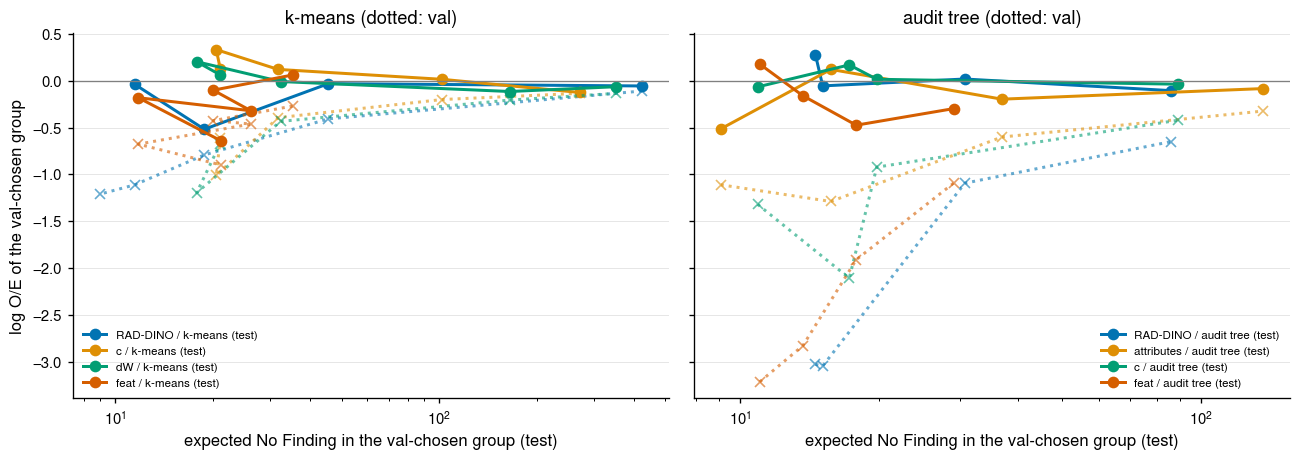

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for axis, family in zip(axes, ("k-means", "audit tree")):
    part = sweep[sweep.partition.str.endswith(family)]
    for name, rows in part.groupby("partition"):
        mean = rows.groupby("setting")[["val_chosen_test_expected", "val_chosen_test_log_oe", "val_chosen_val_log_oe"]].mean()
        line = axis.plot(mean.val_chosen_test_expected, mean.val_chosen_test_log_oe, marker="o", label=f"{name} (test)")
        axis.plot(mean.val_chosen_test_expected, mean.val_chosen_val_log_oe, marker="x", ls=":", color=line[0].get_color(), alpha=0.6)
    axis.set_xscale("log")
    axis.axhline(0, color="gray", lw=0.8)
    axis.set_xlabel("expected No Finding in the val-chosen group (test)")
    axis.set_title(f"{family} (dotted: val)")
axes[0].set_ylabel("log O/E of the val-chosen group")
for axis in axes:
    axis.legend(fontsize=7)
fig.tight_layout()
fig.savefig(FIGURES / "granularity_sweep.png", dpi=150)
plt.show()

## 4. 小さな部分集団：k 近傍の球の残差の走査

val の各行を中心に k 近傍の球を作り、残差の z 値（Σ(y − p) / √Σp(1 − p)）が最小の球を選ぶ。帰無分布は y を
Bernoulli(p) で引き直した最小 z 値。選んだ球の半径を test に当てて O/E を測る。空間は特徴と RAD-DINO（PCA 32 次元）と c。
c は属性の関数なので、同じセルの行は距離 0 で重なる（球はセルの束になる）。

In [9]:
SCAN_KS = [50, 100, 200, 500, 1000]
scan_rows, BALLS = [], {}
for seed in RUNS:
    val, test = DATA[seed]["val"].frame, DATA[seed]["test"].frame
    p_val, p_test = PROB[seed]
    for name, key in (("c", "c"), ("feat", "feat32"), ("RAD-DINO", "rad32")):
        for k in SCAN_KS:
            result = sg.knn_residual_scan(*SPACES[seed][key], val.target.to_numpy(), p_val, test.target.to_numpy(), p_test, k)
            BALLS[(seed, name, k)] = result
            scan_rows.append({key_: value for key_, value in result.items() if not key_.startswith("ball_rows")} | {"seed": seed, "space": name})
scan = pd.DataFrame(scan_rows)
scan.to_csv(RESULTS / "knn_residual_scan.csv", index=False)
display(scan.groupby(["space", "k"])[["val_z", "p_value", "val_log_oe", "test_n_in_ball", "test_expected", "test_log_oe"]].mean().round(3))
display(scan[["seed", "space", "k", "val_z", "p_value", "val_log_oe", "test_n_in_ball", "test_log_oe"]].round(3))

val_z  p_value  val_log_oe  test_n_in_ball  test_expected  \
space    k                                                                 
RAD-DINO 50   -3.451    0.350      -1.530          34.000          6.292   
         100  -3.519    0.387      -0.880          96.333         18.936   
         200  -3.825    0.287      -0.783         193.000         28.377   
         500  -4.631    0.030      -1.004         529.000         44.118   
         1000 -5.163    0.013      -0.731         937.000         66.819   
c        50   -3.356    0.190      -2.334          64.000          5.833   
         100  -3.104    0.277      -1.191         128.667         17.064   
         200  -3.360    0.210      -1.201         209.667         26.230   
         500  -3.531    0.047      -0.439         467.000         67.098   
         1000 -3.781    0.033      -0.325         994.333        139.645   
feat     50   -3.498    0.290      -0.813          49.667         21.058   
         100  -3.746    0.223      -1.132         100.333         32.427   
         200  -3.652    0.293      -0.565         192.667         59.319   
         500  -3.862    0.273      -0.986         498.000         84.135   
         1000 -4.150    0.077      -0.905        1035.000         86.511   

               test_log_oe  
space    k                  
RAD-DINO 50         -0.411  
         100        -0.059  
         200        -0.191  
         500        -0.226  
         1000       -0.466  
c        50          0.171  
         100        -0.035  
         200        -0.061  
         500        -0.148  
         1000       -0.105  
feat     50         -0.075  
         100        -0.012  
         200        -0.038  
         500        -0.213  
         1000       -0.508

,seed,space,k,val_z,p_value,val_log_oe,test_n_in_ball,test_log_oe
0,42,c,50,-3.898,0.02,-2.955,64,0.249
1,42,c,100,-3.291,0.16,-0.942,152,0.119
2,42,c,200,-3.576,0.04,-2.147,201,0.199
3,42,c,500,-3.390,0.04,-0.561,435,-0.109
4,42,c,1000,-3.435,0.07,-0.404,1068,-0.059
5,42,feat,50,-3.298,0.42,-0.785,52,-0.129
6,42,feat,100,-3.977,0.06,-1.936,94,-0.230
7,42,feat,200,-3.746,0.16,-0.892,161,-0.029
8,42,feat,500,-4.271,0.02,-0.573,506,-0.139
9,42,feat,1000,-4.013,0.07,-0.321,1026,-0.201


### 走査で見つけた球の中身（k = 200、val の行）

In [10]:
ball_rows = []
for (seed, name, k), result in BALLS.items():
    if k != 200:
        continue
    frame = with_factor_columns(DATA[seed]["val"].frame)
    mask = np.zeros(len(frame), dtype=bool)
    mask[result["ball_rows_val"]] = True
    ball_rows.append(share_ratio(mask, frame).assign(seed=seed, space=name))
balls = pd.concat(ball_rows, ignore_index=True)
balls.to_csv(RESULTS / "knn_ball_enrichment_k200.csv", index=False)
display(balls.pivot_table(index="factor", columns=["space", "seed"], values="share_in_group").loc[FACTORS].round(2))
display(balls.groupby("factor").share_overall.mean().loc[FACTORS].round(2).rename("share_overall"))

space                         RAD-DINO                 c              feat  \
seed                                42    43    44    42    43    44    42   
factor                                                                       
young                             0.92  0.66  0.41  0.73  1.00  1.00  0.62   
female                            0.06  0.02  0.02  0.00  1.00  1.00  0.40   
black                             0.14  0.25  0.08  0.46  0.00  0.00  0.21   
asian                             0.05  0.02  0.02  0.00  0.00  0.00  0.03   
pa                                0.02  0.88  0.02  0.00  0.00  0.00  0.02   
lateral                           0.00  0.00  0.00  0.00  0.00  0.00  0.00   
affirmed_normal                   0.16  0.20  0.09  0.04  0.06  0.06  0.12   
followup                          0.56  0.68  0.68  0.74  0.66  0.66  0.56   
device                            0.68  0.45  0.66  0.67  0.70  0.70  0.50   
pacer                             0.00  0.00  0.01  0.10  0.12  0.12  0.06   
picc                              0.10  0.08  0.13  0.12  0.06  0.06  0.12   
central_line                      0.15  0.18  0.12  0.42  0.34  0.34  0.19   
sternotomy                        0.02  0.01  0.02  0.17  0.15  0.15  0.07   
surgical_clip                     0.04  0.08  0.04  0.04  0.15  0.15  0.06   
dz_Enlarged Cardiomediastinum     0.03  0.04  0.02  0.02  0.03  0.03  0.03   
dz_Cardiomegaly                   0.02  0.08  0.02  0.10  0.22  0.22  0.13   
dz_Lung Opacity                   0.34  0.39  0.45  0.54  0.55  0.55  0.33   
dz_Lung Lesion                    0.06  0.08  0.06  0.02  0.02  0.02  0.06   
dz_Edema                          0.06  0.04  0.10  0.28  0.24  0.24  0.15   
dz_Consolidation                  0.04  0.06  0.03  0.04  0.06  0.06  0.02   
dz_Pneumonia                      0.02  0.04  0.02  0.00  0.02  0.02  0.01   
dz_Atelectasis                    0.09  0.10  0.13  0.18  0.12  0.12  0.20   
dz_Pneumothorax                   0.32  0.05  0.34  0.10  0.10  0.10  0.04   
dz_Pleural Effusion               0.18  0.24  0.26  0.59  0.43  0.43  0.12   
dz_Pleural Other                  0.02  0.06  0.04  0.00  0.00  0.00  0.02   
dz_Fracture                       0.10  0.05  0.08  0.07  0.01  0.01  0.05   
dz_Support Devices                0.62  0.36  0.57  0.70  0.67  0.67  0.52   

space                                      
seed                             43    44  
factor                                     
young                          0.93  0.84  
female                         0.31  0.45  
black                          0.24  0.17  
asian                          0.08  0.09  
pa                             0.93  0.26  
lateral                        0.02  0.01  
affirmed_normal                0.38  0.28  
followup                       0.67  0.45  
device                         0.32  0.44  
pacer                          0.00  0.08  
picc                           0.08  0.10  
central_line                   0.14  0.20  
sternotomy                     0.03  0.05  
surgical_clip                  0.05  0.06  
dz_Enlarged Cardiomediastinum  0.02  0.05  
dz_Cardiomegaly                0.06  0.08  
dz_Lung Opacity                0.16  0.20  
dz_Lung Lesion                 0.06  0.06  
dz_Edema                       0.02  0.14  
dz_Consolidation               0.02  0.01  
dz_Pneumonia                   0.02  0.01  
dz_Atelectasis                 0.02  0.13  
dz_Pneumothorax                0.02  0.04  
dz_Pleural Effusion            0.04  0.04  
dz_Pleural Other               0.02  0.01  
dz_Fracture                    0.06  0.06  
dz_Support Devices             0.24  0.41

factor
young                            0.55
female                           0.40
black                            0.18
asian                            0.06
pa                               0.13
lateral                          0.15
affirmed_normal                  0.11
followup                         0.72
device                           0.57
pacer                            0.08
picc                             0.12
central_line                     0.23
sternotomy                       0.11
surgical_clip                    0.06
dz_Enlarged Cardiomediastinum    0.03
dz_Cardiomegaly                  0.14
dz_Lung Opacity                  0.47
dz_Lung Lesion                   0.04
dz_Edema                         0.23
dz_Consolidation                 0.06
dz_Pneumonia                     0.02
dz_Atelectasis                   0.15
dz_Pneumothorax                  0.08
dz_Pleural Effusion              0.41
dz_Pleural Other                 0.02
dz_Fracture                      0.03
dz_Su

## 5. 見つけた群を性能で見る

ここまでの物差しは較正のずれ（log O/E）だけで、主指標の性能を見ていない。較正のずれが大きい群が、
0.5 の FPR でも悪いとは限らない。val で選んだ群について、test の FPR・TPR・AUROC と、補集合との差
（gap = 群 − 補集合）を出す。

群の選び方は 2 通りにする。

- `log_oe`：log O/E が最小の群（ここまでの選び方）
- `mean_residual`：平均残差 (O − E)/n が最小の群（multiaccuracy の定義どおりの差）

AUROC は、得点で選んだ群ほど得点の幅が狭く、低めに出る。FPR の gap と並べて読む。

In [11]:
overall_rows = []
for seed in RUNS:
    test = DATA[seed]["test"].frame
    overall_rows.append({"seed": seed} | sg.rates(test.target.to_numpy(), test.pred.to_numpy(), test.margin.to_numpy()))
overall = pd.DataFrame(overall_rows)
display(overall.round(3))

,seed,n,n_pos,n_neg,prevalence,fpr,tpr,auroc
0,42,19617,2044,17573,0.104,0.304,0.870,0.862
1,43,19617,2044,17573,0.104,0.207,0.798,0.862
2,44,19617,2044,17573,0.104,0.229,0.823,0.863


### val で選んだ群の、test の性能

`same_group` は、2 つの選び方が同じ群を選んだ割合（3 seed）。

In [12]:
PERFORMANCE_COLUMNS = ["n", "prevalence", "fpr", "rest_fpr", "gap_fpr", "tpr", "gap_tpr", "auroc", "gap_auroc", "log_oe", "mean_residual"]
chosen_perf_rows = []
for (seed, name), (val_groups, test_groups) in PARTITIONS.items():
    val, test = DATA[seed]["val"].frame, DATA[seed]["test"].frame
    p_val, p_test = PROB[seed]
    val_table = sg.calibration_table(val_groups, val.target.to_numpy(), p_val)
    picks = {criterion: val_table[criterion].idxmin() for criterion in ("log_oe", "mean_residual")}
    for criterion, group in picks.items():
        row = sg.performance_of(test_groups == group, test, p_test)
        chosen_perf_rows.append(row | {"seed": seed, "partition": name, "criterion": criterion, "same_group": picks["log_oe"] == picks["mean_residual"]})
chosen_perf = pd.DataFrame(chosen_perf_rows)
chosen_perf.to_csv(RESULTS / "chosen_group_performance.csv", index=False)
chosen_perf_mean = chosen_perf.groupby(["partition", "criterion"], sort=False)[[*PERFORMANCE_COLUMNS, "same_group"]].mean()
display(chosen_perf_mean.round(3))

n  prevalence    fpr  \
partition                  criterion                                    
score deciles              log_oe         1955.333       0.020  0.000   
                           mean_residual  2032.333       0.182  0.333   
attributes / 8 groups      log_oe          948.333       0.111  0.283   
                           mean_residual   983.333       0.147  0.339   
attributes / 48 fine cells log_oe          334.000       0.078  0.213   
                           mean_residual    79.000       0.253  0.548   
c / k-means                log_oe         2867.000       0.086  0.243   
                           mean_residual  2328.000       0.141  0.313   
dW / k-means               log_oe         3174.333       0.111  0.275   
                           mean_residual  3048.000       0.129  0.318   
feat / LHCF                log_oe         1947.000       0.015  0.005   
                           mean_residual  1924.667       0.298  0.798   
RAD-DINO / LHCF            log_oe         2393.000       0.038  0.095   
                           mean_residual  1792.667       0.064  0.177   
attributes / audit ridge   log_oe         2167.333       0.083  0.216   
                           mean_residual  2167.333       0.083  0.216   
attributes / audit tree    log_oe          644.000       0.074  0.208   
                           mean_residual   667.333       0.139  0.351   
c / audit ridge            log_oe         2135.333       0.085  0.226   
                           mean_residual  2434.667       0.115  0.279   
c / audit tree             log_oe          647.667       0.061  0.161   
                           mean_residual   525.667       0.188  0.417   
feat / audit ridge         log_oe         2461.000       0.125  0.381   
                           mean_residual  2461.000       0.125  0.381   
feat / audit tree          log_oe          612.667       0.016  0.013   
                           mean_residual   651.667       0.279  0.797   
RAD-DINO / audit ridge     log_oe         2306.333       0.047  0.181   
                           mean_residual  2406.333       0.064  0.205   
RAD-DINO / audit tree      log_oe          535.667       0.041  0.137   
                           mean_residual   553.667       0.156  0.419   

                                          rest_fpr  gap_fpr    tpr  gap_tpr  \
partition                  criterion                                          
score deciles              log_oe            0.276   -0.276  0.000   -0.847   
                           mean_residual     0.252    0.081  0.333   -0.448   
attributes / 8 groups      log_oe            0.245    0.038  0.792   -0.040   
                           mean_residual     0.242    0.098  0.860    0.033   
attributes / 48 fine cells log_oe            0.247   -0.034  0.679   -0.153   
                           mean_residual     0.245    0.303  0.883    0.053   
c / k-means                log_oe            0.248   -0.005  0.834    0.006   
                           mean_residual     0.238    0.076  0.901    0.084   
dW / k-means               log_oe            0.245    0.031  0.858    0.035   
                           mean_residual     0.241    0.076  0.863    0.043   
feat / LHCF                log_oe            0.277   -0.273  0.011   -0.831   
                           mean_residual     0.201    0.596  0.899    0.138   
RAD-DINO / LHCF            log_oe            0.269   -0.174  0.456   -0.392   
                           mean_residual     0.261   -0.084  0.625   -0.215   
attributes / audit ridge   log_oe            0.250   -0.035  0.804   -0.028   
                           mean_residual     0.250   -0.035  0.804   -0.028   
attributes / audit tree    log_oe            0.248   -0.040  0.645   -0.188   
                           mean_residual     0.243    0.107  0.871    0.043   
c / audit ridge            log_oe            0.249   -0.023  0.829   -0.001   
                           mean_residual     0.242   

seed ごとの値（gap の符号が seed で揃うか）。

In [13]:
display(
    chosen_perf[chosen_perf.criterion == "log_oe"]
    .pivot_table(index="partition", columns="seed", values=["gap_fpr", "gap_auroc", "log_oe"], sort=False)
    .loc[METHODS]
    .round(3)
)

gap_fpr               gap_auroc                \
seed                            42     43     44        42     43     44   
partition                                                                  
score deciles               -0.340 -0.232 -0.258    -0.317 -0.399 -0.366   
attributes / 8 groups        0.072  0.090 -0.048    -0.027 -0.021 -0.018   
attributes / 48 fine cells  -0.064 -0.012 -0.025    -0.051 -0.037 -0.083   
c / k-means                 -0.066  0.082 -0.031    -0.035  0.013  0.017   
dW / k-means                -0.097  0.114  0.074    -0.026  0.016  0.001   
feat / LHCF                 -0.352 -0.225 -0.241    -0.285 -0.339 -0.358   
RAD-DINO / LHCF             -0.196 -0.166 -0.159    -0.097 -0.103 -0.120   
attributes / audit ridge    -0.053 -0.000 -0.050     0.001  0.007 -0.035   
attributes / audit tree     -0.113 -0.052  0.046    -0.116 -0.101  0.032   
c / audit ridge             -0.043  0.015 -0.039    -0.005  0.025 -0.034   
c / audit tree              -0.092 -0.085 -0.090    -0.009 -0.113 -0.039   
feat / audit ridge           0.308  0.080  0.075    -0.052 -0.001  0.029   
feat / audit tree           -0.303 -0.215 -0.207       NaN    NaN    NaN   
RAD-DINO / audit ridge      -0.029 -0.132 -0.063    -0.041 -0.039 -0.061   
RAD-DINO / audit tree       -0.032 -0.109 -0.198    -0.002 -0.012    NaN   

                           log_oe                
seed                           42     43     44  
partition                                        
score deciles               0.268  0.273 -0.244  
attributes / 8 groups      -0.016 -0.010 -0.200  
attributes / 48 fine cells -0.100 -0.044 -0.077  
c / k-means                -0.130 -0.069 -0.178  
dW / k-means               -0.068 -0.040 -0.085  
feat / LHCF                -0.088 -0.069 -0.336  
RAD-DINO / LHCF            -0.034  0.050 -0.088  
attributes / audit ridge   -0.066 -0.050 -0.063  
attributes / audit tree    -0.139 -0.074 -0.033  
c / audit ridge            -0.111 -0.048 -0.125  
c / audit tree             -0.099  0.319 -0.045  
feat / audit ridge         -0.241 -0.111 -0.152  
feat / audit tree          -0.035 -0.630 -0.427  
RAD-DINO / audit ridge     -0.371 -0.479 -0.171  
RAD-DINO / audit tree      -0.316 -0.162 -0.029

### 群をまたいで、較正のずれと性能は並ぶか

各分割の test の群（期待陽性数 10 以上）で、log O/E・平均残差と、FPR・AUROC の Spearman 相関を取る。
較正のずれが性能の悪さと同じ向き（log O/E が低い群ほど FPR が高い）なら負になる。

In [14]:
corr_rows = []
for (seed, name), (_, test_groups) in PARTITIONS.items():
    test = DATA[seed]["test"].frame
    p_test = PROB[seed][1]
    calibration = sg.calibration_table(test_groups, test.target.to_numpy(), p_test)
    performance = sg.group_table(test_groups, test).set_index("group")
    table = calibration.join(performance[["fpr", "auroc"]]).dropna(subset=["log_oe"])
    row = {"seed": seed, "partition": name, "groups": len(table)}
    for x in ("log_oe", "mean_residual"):
        for y in ("fpr", "auroc"):
            row[f"{x}_vs_{y}"] = table[x].corr(table[y], method="spearman")
    corr_rows.append(row)
corr = pd.DataFrame(corr_rows)
corr.to_csv(RESULTS / "calibration_vs_performance.csv", index=False)
display(corr.groupby("partition", sort=False).mean(numeric_only=True).drop(columns="seed").loc[METHODS].round(2))

,groups,log_oe_vs_fpr,log_oe_vs_auroc,mean_residual_vs_fpr,mean_residual_vs_auroc
partition,,,,,
score deciles,10.00,-0.25,-0.29,0.29,0.25
attributes / 8 groups,8.00,-0.44,-0.24,-0.17,-0.17
attributes / 48 fine cells,34.00,0.26,-0.27,0.36,-0.18
c / k-means,8.00,0.21,-0.38,0.33,-0.36
dW / k-means,8.00,0.28,-0.53,0.49,-0.43
feat / LHCF,12.00,-0.21,0.15,-0.12,0.22
RAD-DINO / LHCF,10.00,0.41,0.05,0.44,-0.07
attributes / audit ridge,8.00,0.34,-0.26,0.29,-0.37
attributes / audit tree,28.33,0.13,-0.34,0.09,-0.39


### k 近傍の球の性能

4 節の走査で val で選んだ球を test に当てたときの性能。

In [15]:
ball_perf_rows = []
for (seed, name, k), result in BALLS.items():
    test = DATA[seed]["test"].frame
    mask = np.zeros(len(test), dtype=bool)
    mask[result["ball_rows_test"]] = True
    ball_perf_rows.append(sg.performance_of(mask, test, PROB[seed][1]) | {"seed": seed, "space": name, "k": k})
ball_perf = pd.DataFrame(ball_perf_rows)
ball_perf.to_csv(RESULTS / "knn_ball_performance.csv", index=False)
display(ball_perf.groupby(["space", "k"])[PERFORMANCE_COLUMNS].mean().round(3))

n  prevalence    fpr  rest_fpr  gap_fpr    tpr  gap_tpr  \
space    k                                                                      
RAD-DINO 50      34.000       0.118  0.600     0.246    0.354    NaN      NaN   
         100     96.333       0.187  0.526     0.245    0.281  0.938    0.092   
         200    193.000       0.131  0.421     0.245    0.176  0.828   -0.007   
         500    529.000       0.066  0.215     0.247   -0.032  0.818   -0.029   
         1000   937.000       0.045  0.211     0.248   -0.037  0.661   -0.172   
c        50      64.000       0.109  0.211     0.246   -0.036    NaN      NaN   
         100    128.667       0.129  0.291     0.246    0.045  0.955    0.122   
         200    209.667       0.113  0.306     0.246    0.060  0.846    0.036   
         500    467.000       0.126  0.346     0.244    0.102  0.889    0.062   
         1000   994.333       0.129  0.334     0.242    0.092  0.911    0.087   
feat     50      49.667       0.410  1.000     0.245    0.735  1.000    0.205   
         100    100.333       0.330  1.000     0.243    0.757  1.000    0.194   
         200    192.667       0.289  1.000     0.240    0.760  1.000    0.175   
         500    498.000       0.144  0.667     0.236    0.430  1.000    0.163   
         1000  1035.000       0.061  0.355     0.242    0.113  0.586   -0.260   

               auroc  gap_auroc  log_oe  mean_residual  
space    k                                              
RAD-DINO 50      NaN        NaN  -0.411         -0.067  
         100   0.849     -0.013  -0.059         -0.007  
         200   0.770     -0.092  -0.191         -0.019  
         500   0.855     -0.008  -0.226         -0.017  
         1000  0.809     -0.054  -0.466         -0.026  
c        50      NaN        NaN   0.171          0.018  
         100   0.889      0.028  -0.035         -0.003  
         200   0.849     -0.014  -0.061         -0.012  
         500   0.840     -0.022  -0.148         -0.018  
         1000  0.868      0.007  -0.105         -0.014  
feat     50      NaN        NaN  -0.075         -0.026  
         100   0.581     -0.280  -0.012          0.011  
         200   0.594     -0.268  -0.038         -0.013  
         500   0.611     -0.254  -0.213         -0.015  
         1000  0.634     -0.233  -0.508         -0.022

## まとめ

観察と解釈は [reports/space_comparison.md](reports/space_comparison.md) に 02 とあわせて書く。